# Lesson 05 · Bayesian A/B testing

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 6 (pp. 45–54)

**Question:** Mike Piazza hit .308 over his career and Hank Aaron hit .305. Is Piazza really the better hitter, or did he just get luckier?

**Goal:** Compute the probability that one player's true average beats another's in four ways: simulation, numerical integration, an exact formula and a normal approximation. Then build a credible interval for the difference and compare it with the classical test.

**Contents**

1. Setup (a new pitcher rule)
2. Two posteriors side by side
3. Route 1: simulation
4. Route 2: numerical integration
5. Route 3: the exact formula
6. Route 4: normal approximation
7. Credible vs confidence intervals for a difference
8. Exercises

**Tags:** `ab-testing` `comparing-proportions` `posterior-simulation` `numerical-integration` `normal-approximation` `chi-squared`

**Before you start:** Lesson 03.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [1]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

# From here on the book only drops players who pitched in MORE than 3 games
# (so Ty Cobb, who pitched a couple of times, stays in).
career = eb_data.career(pitcher_rule=3)
alpha0, beta0 = eb_data.load_prior()
print(f"{len(career):,} players | prior alpha0 = {alpha0:.1f}, beta0 = {beta0:.1f}")

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
13,446 players | prior alpha0 = 95.3, beta0 = 271.5


## 1. Setup

**5.1.1 · Your turn.** Add `eb_estimate`, `alpha1` and `beta1`. Pull out the rows for Hank Aaron, Mike Piazza and Hideki Matsui.

In [2]:
# 5.1.1 · Your code here
career['alpha1'] = alpha0 + career.H
career['beta1'] = beta0 + career.AB - career.H
career['eb_estimate'] = (career.alpha1 / (career.alpha1 + career.beta1))
players = career[career['name'].isin(['Hank Aaron', 'Mike Piazza', 'Hideki Matsui'])]
players

,playerID,name,H,AB,average,alpha1,beta1,eb_estimate
0,aaronha01,Hank Aaron,3771,12364,0.3050,3866.3306,8864.4864,0.3037
7641,matsuhi01,Hideki Matsui,1253,4442,0.2821,1348.3306,3460.4864,0.2804
9516,piazzmi01,Mike Piazza,2127,6911,0.3078,2222.3306,5055.4864,0.3054


## 2. Two posteriors side by side

**5.2.1 · Your turn.** Plot the posterior densities of Aaron and Piazza, then add Matsui.

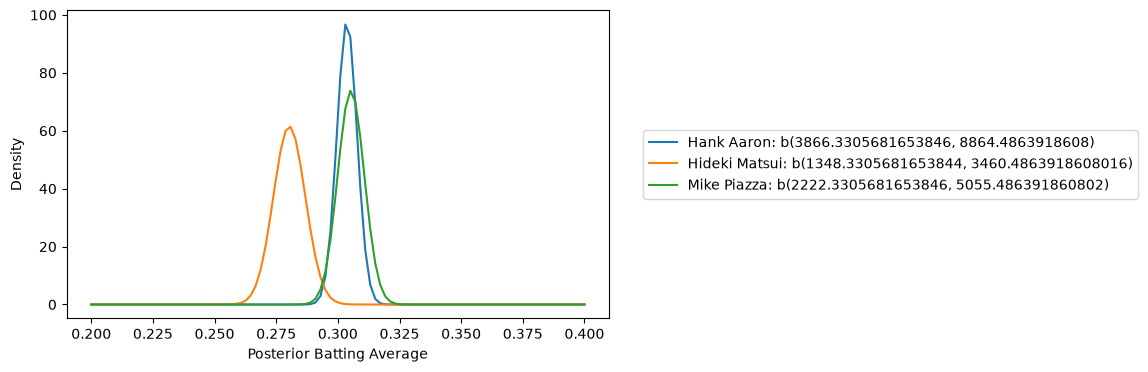

In [3]:
# 5.2.1 · Your code here
x = np.linspace(0.2, 0.4, 100)
for i in range(len(players)):
    name = players.iloc[i]['name']
    a1 = players.iloc[i].alpha1
    b1 = players.iloc[i].beta1
    plt.plot(x, stats.beta(a1, b1).pdf(x), label = f"{name}: B({a1}, {b1})")

plt.xlabel("Posterior Batting Average")
plt.ylabel("Density")
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show()


**5.2.2 · Reflect.** From the picture alone, roughly what's the probability that Piazza is better than Aaron? What about Matsui versus Piazza?

*5.2.2 · Your answer:*
Both Aaron and Piazza are quite confidently better than Matsui, but it would be very difficult to tell Aaron and Piazza part. I think based on the fact that Piazza's distribution has a good portion that extended beyond Aaron's, that if either is better it would be much more likely to be Piazza.

## 3. Route 1: simulation

Draw many values from each posterior and count how often Piazza's draw is bigger. No maths needed, and it extends to almost any model. This is the same reason MCMC works.

**5.3.1 · Your turn.** Estimate P(p_Piazza > p_Aaron) with 1,000,000 draws each. Time it with `%timeit` (or `time.perf_counter`).

In [4]:
# 5.3.1 · Your code here
import time
aaron = players[players['name'] == 'Hank Aaron']
piazza = players[players['name'] == 'Mike Piazza']

aa, ba = (aaron.alpha1.item(), aaron.beta1.item())
ab, bb = (piazza.alpha1.item(), piazza.beta1.item())
alphabeta = [aa, ba, ab, bb]

rng = np.random.default_rng()
n = 1000000
def simit(AA, BA, AB, BB):
    starttime = time.perf_counter()
    global n
    p_Aaron = rng.beta(AA, BA, n)
    p_Piazza= rng.beta(AB, BB, n)
    result = p_Piazza > p_Aaron
    stoptime = time.perf_counter()
    return sum(result)/n, stoptime - starttime
simit(*alphabeta)

(np.float64(0.596439), 0.12882929999977932)

> **Check:** ≈ 0.595.

## 4. Route 2: numerical integration

The two posteriors are independent, so their joint density is the product. We want the mass of the region where $x_{Piazza} > y_{Aaron}$:

$$\Pr = \iint_{x > y} f_P(x)\, f_A(y)\, dx\, dy.$$

**5.4.1 · Your turn.** Approximate the integral on a grid from 0.29 to 0.33 with spacing 0.00002 (or coarser at first). `np.meshgrid` or broadcasting with `[:, None]` will help. Plot the joint density as a contour with the line x = y.

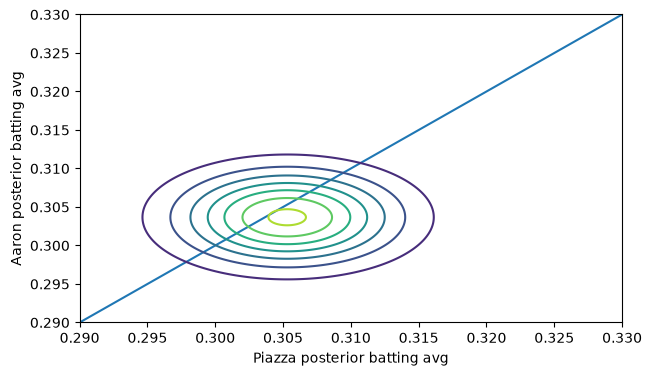

Probability of Piazza's batting avg > Aaron's batting avg: 0.595495357850828


In [5]:
# 5.4.1 · Your code here
spacing = 0.00002
start = 0.29
stop = 0.33

x = np.arange(start, stop, spacing)
y = np.arange(start, stop, spacing)
X, Y = np.meshgrid(x, y)
Z = []

def numint(AA, BA, AB, BB):
    global X, Y, Z
    starttime = time.perf_counter()
    Z = (stats.beta(AB, BB).pdf(X)) * (stats.beta(AA, BA).pdf(Y))
    p_BmoreA = np.sum(Z * (X > Y))*(spacing ** 2)
    stoptime = time.perf_counter()
    return(p_BmoreA, stoptime - starttime)

plt.plot(x, y)
(p_PA, elapsed) = numint(*alphabeta)
plt.contour(X, Y, Z)
plt.xlabel("Piazza posterior batting avg")
plt.ylabel("Aaron posterior batting avg")
plt.show()


print(f"Probability of Piazza's batting avg > Aaron's batting avg: {p_PA}")

## 5. Route 3: the exact formula

Evan Miller derived a closed form for two beta posteriors. With $A \sim \text{Beta}(\alpha_A, \beta_A)$ and $B \sim \text{Beta}(\alpha_B, \beta_B)$, and $\alpha_B$ an integer:

$$\Pr(p_B > p_A) = \sum_{i=0}^{\alpha_B - 1} \frac{B(\alpha_A + i,\; \beta_A + \beta_B)}{(\beta_B + i)\, B(1 + i,\; \beta_B)\, B(\alpha_A, \beta_A)},$$

where $B$ is the beta function. Work on the log scale with `special.betaln` to avoid overflow. Our $\alpha$ values aren't whole numbers, so round $\alpha_B$ as the book does.

**5.5.1 · Your turn.** Write `prob_b_beats_a(alpha_a, beta_a, alpha_b, beta_b)` and compute P(Piazza > Aaron), with Piazza as B.

In [6]:
# 5.5.1 · Your code here
def prob_B_beats_A(AA, BA, AB, BB):
    starttime = time.perf_counter()
    p=0
    i = np.arange(0, np.floor(AB)) #Since we want AB-1, so arange would need argument (AB-1) + 1 = AB
    exp = (special.betaln(AA + i, BA + BB)) - (np.log(BB + i) + (special.betaln(1+i, BB)) + (special.betaln(AA, BA)))
    stoptime = time.perf_counter()
    return (np.exp(exp).sum(), stoptime - starttime)

print(prob_B_beats_A(*alphabeta))

(np.float64(0.5946115250619021), 0.0011256999969191384)


> **Check:** ≈ 0.59–0.60. Rounding α_B shifts the last digit, so the routes agree to about two decimal places.

## 6. Route 4: normal approximation

With large $\alpha$ and $\beta$, a beta looks normal, with mean $\alpha/(\alpha+\beta)$ and variance $\alpha\beta / ((\alpha+\beta)^2(\alpha+\beta+1))$. The difference of two independent normals is normal, so the probability is one call to `stats.norm.cdf`.

**5.6.1 · Your turn.** Write `prob_b_beats_a_approx(...)`. It should work on whole arrays. Compare all four routes in a table with their run times.

In [7]:
# 5.6.1 · Your code here
def prob_B_beats_A_approx(AA, BA, AB, BB):
    starttime = time.perf_counter()
    mean1 = AA/(AA + BA)
    mean2 = AB/(AB + BB)
    var1 = (AA * BA) / (((AA + BA)**2) * (AA + BA + 1))
    var2 = (AB * BB) / (((AB + BB)**2) * (AB + BB + 1))
    p_BmoreA = 1 - (stats.norm.cdf(0, mean2 - mean1, np.sqrt(var1 + var2)))
    stoptime = time.perf_counter()
    return(p_BmoreA, stoptime - starttime)

prob_B_beats_A_approx(*alphabeta)

(np.float64(0.5968320359329603), 0.00038720000156899914)

In [8]:
print( 'Comparison:') 

results = [simit(*alphabeta), numint(*alphabeta), prob_B_beats_A(*alphabeta),prob_B_beats_A_approx(*alphabeta)]

# Create the DataFrame
comparison = pd.DataFrame(
    results, columns=['p(Piazza > Aaron)', 'Time (ms)'], index=["Simulation", "Numerical Integration", "Exact", "Normal approx"]
)
comparison = comparison.rename_axis('Method')
print(comparison)

Comparison:
                       p(Piazza > Aaron)  Time (ms)
Method                                             
Simulation                        0.5960     0.1388
Numerical Integration             0.5955     1.5996
Exact                             0.5946     0.0005
Normal approx                     0.5968     0.0003


**5.6.2 · Reflect.** When would the normal approximation go wrong? Why is it safe with a prior as strong as ours?

*5.6.2 · Your answer:*

The normal approximation of a beta distribution fails with low alpha or beta values, which doesn't seem to be an issue with the ones we have for Hank and Mike.

## 7. Credible vs confidence intervals for a difference

**5.7.1 · Your turn.** Classical: build the 2×2 table of hits and misses for Aaron and Piazza and run `stats.chi2_contingency`. Then compute a 95% Wald confidence interval for the difference in proportions.

In [9]:
# 5.7.1 · Your code here


> **Check:** p-value ≈ 0.7; 95% CI for the difference ≈ (−0.0165, 0.0109).

**5.7.2 · Your turn.** Bayesian: use the normal approximation to get a 95% credible interval for p_Piazza − p_Aaron, along with the posterior probability.

In [10]:
# 5.7.2 · Your code here

**5.7.3 · Your turn.** Pick 20 random players and compare each with Piazza: plot each player's credible interval and confidence interval for the difference, sorted by AB.

In [11]:
# 5.7.3 · Your code here

**5.7.4 · Reflect.** Same question as Lesson 03: when do the two kinds of interval agree, and when does the prior make a difference?

*5.7.4 · Your answer:*

## 8. Exercises

**5.8.1 · Your turn.** Use your vectorized normal approximation to compute, for every player in history, the probability that he's a better hitter than Piazza. How many exceed 95%? Who are they?

In [12]:
# 5.8.1 · Your code here
results, elapsed = prob_B_beats_A_approx(aa, ba, career.alpha1, career.beta1)
career['BetterThanPiazza?'] = results
career = career.sort_values('BetterThanPiazza?', ascending = False)
betterthanpiazza = career[career['BetterThanPiazza?'] > 0.95]
print(f"Number of players better than Mike Piazza: {len(betterthanpiazza)}\n")
betterthanpiazza

Number of players better than Mike Piazza: 63



,playerID,name,H,AB,average,alpha1,beta1,eb_estimate,BetterThanPiazza?
2226,cobbty01,Ty Cobb,4189,11436,0.3663,4284.3306,7518.4864,0.3630,1.0000
5591,hornsro01,Rogers Hornsby,2930,8173,0.3585,3025.3306,5514.4864,0.3543,1.0000
11423,speaktr01,Tris Speaker,3514,10195,0.3447,3609.3306,6952.4864,0.3417,1.0000
5858,jacksjo01,Shoeless Joe Jackson,1772,4981,0.3558,1867.3306,3480.4864,0.3492,1.0000
2952,delahed01,Ed Delahanty,2597,7510,0.3458,2692.3306,5184.4864,0.3418,1.0000
...,...,...,...,...,...,...,...,...,...
7257,lundydi01,Dick Lundy,952,2909,0.3273,1047.3306,2228.4864,0.3197,0.9607
10649,santolo99,Louis Santop,493,1448,0.3405,588.3306,1226.4864,0.3242,0.9598
3919,fothebo01,Bob Fothergill,1064,3269,0.3255,1159.3306,2476.4864,0.3189,0.9587
12846,wheatza01,Zack Wheat,2884,9106,0.3167,2979.3306,6493.4864,0.3145,0.9576


**5.8.2 · Your turn.** **Card connection.** Collectible cards are often *graded*: sent to a company that authenticates the card, scores its condition from 1 to 10 and seals it in a plastic case. Graded cards are widely resold on eBay, and a seller's *sell-through rate* is the fraction of their listings that actually sell.

Two eBay sellers list the same graded card. Seller A sold 18 of 40 listings and Seller B sold 7 of 12. Using a beta prior that you justify, what's the probability that A's true sell-through rate is higher? Try at least two routes from this lesson.

In [13]:
# 5.8.2 · Your code here
print(
'''
A quick google search shows that the average sell through rate is estimated to be 15-30%,
although this can be skewed towards auction houses that have resources to purchase and sell 
high grade items and have rates as high as 60%.
We'll assume our sellers are 'average' people, and estimate the mean of their beta prior around 30%,
with the spread encompassing as low as 15% or as high 45%, meaning 3 standard deviations should cover 
15% of probability:
''')

b_mean = 0.30
sig = 0.05
nu =( ((b_mean * (1-b_mean)) / (sig **2)) - 1)
alpha0 = b_mean * nu
beta0 = nu - alpha0
print(alpha0, beta0)

data = [
    ["A", 18, 40, alpha0, beta0],
    ["B", 7, 12, alpha0, beta0],
]
sellers = pd.DataFrame(data, columns=["Name", "Sales", "Listings", "Alpha0", "Beta0"])
sellers


A quick google search shows that the average sell through rate is estimated to be 15-30%,
although this can be skewed towards auction houses that have resources to purchase and sell 
high grade items and have rates as high as 60%.
We'll assume our sellers are 'average' people, and estimate the mean of their beta prior around 30%,
with the spread encompassing as low as 15% or as high 45%, meaning 3 standard deviations should cover 
15% of probability:

24.899999999999995 58.099999999999994


,Name,Sales,Listings,Alpha0,Beta0
0,A,18,40,24.9,58.1
1,B,7,12,24.9,58.1


In [21]:
sellers['Alpha1'] = alpha0 + sellers.Sales
sellers['Beta1'] = beta0 + sellers.Listings - sellers.Sales
sellers['EB_estimate'] = (sellers.Alpha1 / (sellers.Alpha1 + sellers.Beta1))

spacing = 0.002
start = 0.15
stop = 0.45

x = np.arange(start, stop, spacing)
y = np.arange(start, stop, spacing)
X, Y = np.meshgrid(x, y)
Z = []

print( 'Comparison: Is Seller B Better Than A?') 
aa, ba = (sellers.loc[0].Alpha1.item(), sellers.loc[0].Beta1.item())
ab, bb = (sellers.loc[1].Alpha1.item(), sellers.loc[1].Beta1.item())
new_alphabeta = [aa, ba, ab, bb]
results = [simit(*new_alphabeta), numint(*new_alphabeta), prob_B_beats_A(*new_alphabeta),prob_B_beats_A_approx(*new_alphabeta)]

# Create the DataFrame
comparison = pd.DataFrame(
    results, columns=['p(B>A)', 'Time (ms)'], index=["Simulation", "Numerical Integration", "Exact", "Normal approx"]
)
comparison = comparison.rename_axis('Method')
print(comparison)

print(f"""
So it is less likely that Seller B, with 7 out of 12 sales (technically {(7/12)*100:.1f}%), 
is better than A, with 18 out of 40 ({(18/40)*100:.1f}%) sales, even though B has a higher apparent percentage.
Given our prior, of course.
""")

Comparison: Is Seller B Better Than A?
                       p(B>A)   Time (ms)
Method                                   
Simulation             0.4182  1.2738e-01
Numerical Integration  0.4020  9.8735e-03
Exact                  0.3806  5.1000e-05
Normal approx          0.4201  1.4900e-04

So it is less likely that Seller B, with 7 out of 12 sales (technically 58.3%), 
is better than A, with 18 out of 40 (45.0%) sales, even though B has a higher apparent percentage.
Given our prior, of course.



## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 6.
- Evan Miller, "Formulas for Bayesian A/B testing": https://www.evanmiller.org/bayesian-ab-testing.html
- Chris Stucchio, "Bayesian A/B testing at VWO" (whitepaper), for the normal approximation.